<a href="https://colab.research.google.com/github/Pamodya-Wijesinghe/EN3160-Assignment-2-on-Fitting-and-Alignment/blob/main/EN3160_Assignment_02_230727P.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

from pathlib import Path

project_dir = Path("/content/drive/MyDrive/EN3160_Assignment_02")
image_path = project_dir / "images" / "the_berry_farms_sunflower_field.jpeg"
results_dir = project_dir / "results"

results_dir.mkdir(parents=True, exist_ok=True)

print("Image found:", image_path.exists())
print("Image location:", image_path)


Image found: True
Image location: /content/drive/MyDrive/EN3160_Assignment_02/images/the_berry_farms_sunflower_field.jpeg


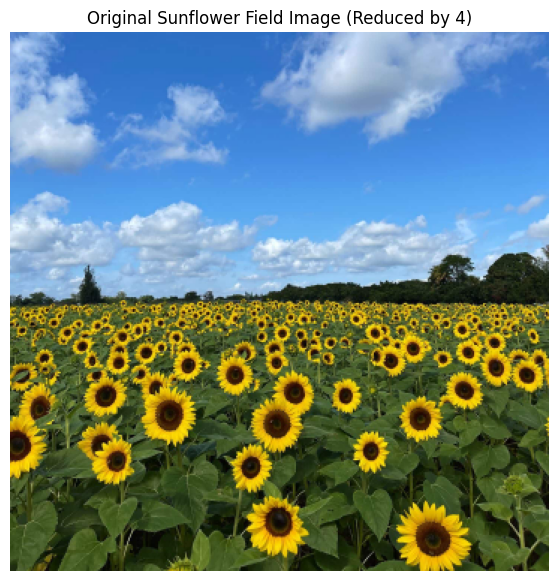

Image dimensions: (360, 360)


In [3]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
import pandas as pd

im = cv.imread(str(image_path), cv.IMREAD_REDUCED_COLOR_4)

assert im is not None, "Image could not be loaded."

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
gray_float = gray.astype(np.float32) / 255.0

plt.figure(figsize=(12, 7))
plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
plt.title("Original Sunflower Field Image (Reduced by 4)")
plt.axis("off")
plt.show()

print("Image dimensions:", gray.shape)


Sigma range: 1.5 to 18.0
Scale-space shape: (360, 360, 34)


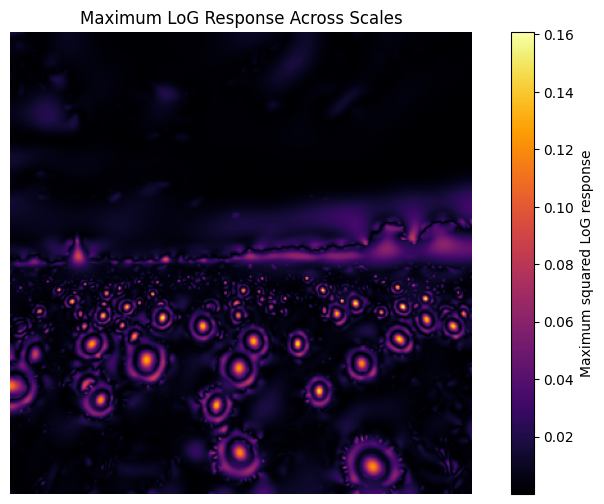

In [4]:

# Range of scales to test
sigmas = np.linspace(1.5, 18.0, 34)

responses = []

for sigma in sigmas:
    # Laplacian of Gaussian
    log_response = gaussian_laplace(gray_float, sigma=sigma)

    # Scale normalization
    normalized_log = sigma**2 * log_response

    # Squared response, as described in Lecture 04
    responses.append(normalized_log**2)

response_stack = np.stack(responses, axis=2)

print("Sigma range:", sigmas.min(), "to", sigmas.max())
print("Scale-space shape:", response_stack.shape)

plt.figure(figsize=(10, 6))
plt.imshow(response_stack.max(axis=2), cmap="inferno")
plt.colorbar(label="Maximum squared LoG response")
plt.title("Maximum LoG Response Across Scales")
plt.axis("off")
plt.show()


In [5]:

# Relative response threshold
threshold_ratio = 0.05

local_max = maximum_filter(
    response_stack,
    size=(3, 3, 3),
    mode="constant"
)

peak_mask = (
    (response_stack == local_max) &
    (response_stack > threshold_ratio * response_stack.max())
)

ys, xs, scale_ids = np.where(peak_mask)

candidates = []

for y, x, k in zip(ys, xs, scale_ids):
    radius = np.sqrt(2) * sigmas[k]

    # Ignore circles extending outside the image
    h, w = gray.shape
    if x-radius < 0 or x+radius >= w:
        continue
    if y-radius < 0 or y+radius >= h:
        continue

    candidates.append({
        "x": int(x),
        "y": int(y),
        "sigma": float(sigmas[k]),
        "radius": float(radius),
        "score": float(response_stack[y, x, k])
    })

# Keep stronger detections first
candidates.sort(key=lambda c: c["score"], reverse=True)

# Remove detections that are too close to an existing circle
detections = []

for candidate in candidates:
    keep = True

    for existing in detections:
        distance = np.hypot(
            candidate["x"] - existing["x"],
            candidate["y"] - existing["y"]
        )

        if distance < 0.7 * max(candidate["radius"], existing["radius"]):
            keep = False
            break

    if keep:
        detections.append(candidate)

print("Number of detected blobs:", len(detections))


Number of detected blobs: 1286


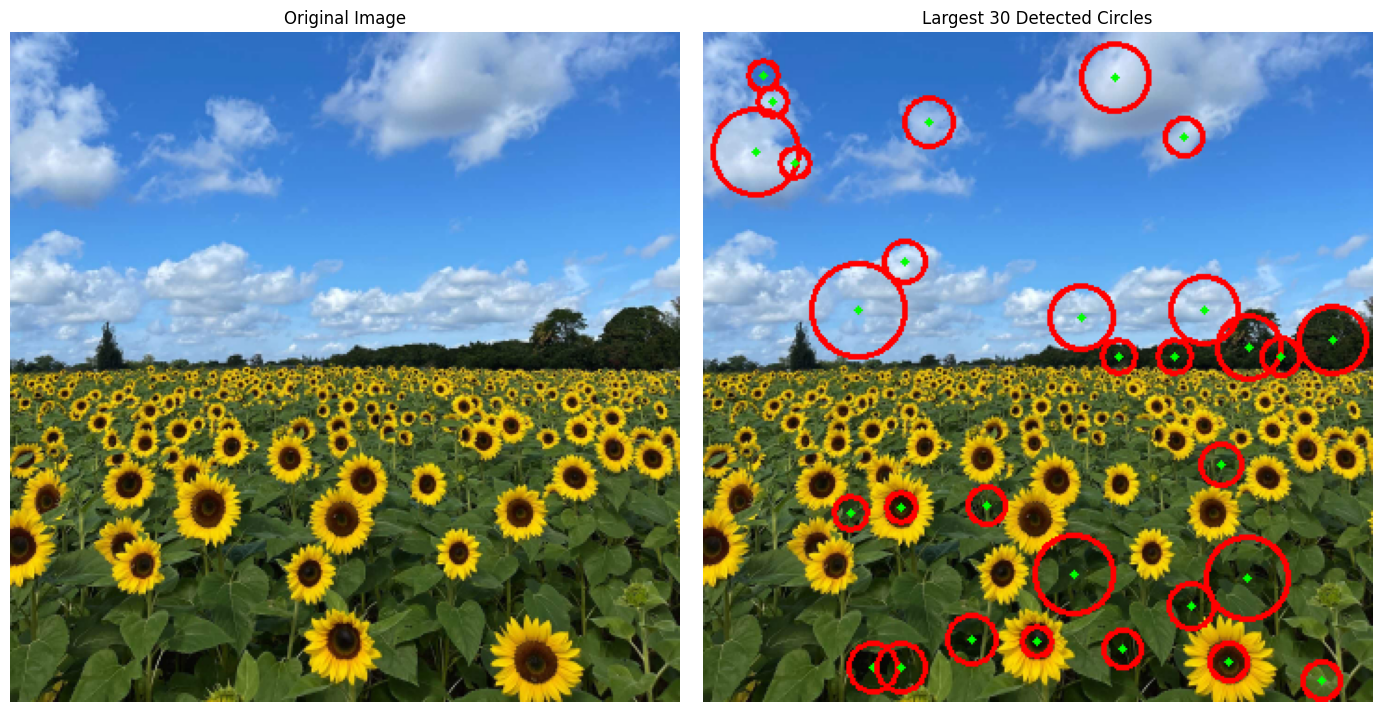

  x   y  sigma    radius    score
 83 149   18.0 25.455844 0.011832
 28  64   16.0 22.627417 0.021368
292 293   15.5 21.920310 0.009154
199 291   14.5 20.506097 0.017827
338 165   13.0 18.384776 0.061010
269 149   12.5 17.677670 0.033192
221  24   12.5 17.677670 0.017317
293 169   12.0 16.970563 0.060590
203 153   12.0 16.970563 0.018352
144 326    9.5 13.435029 0.027697


In [6]:

largest = sorted(
    detections,
    key=lambda c: c["radius"],
    reverse=True
)[:30]

output_image = im.copy()

for blob in largest:
    x = blob["x"]
    y = blob["y"]
    r = int(round(blob["radius"]))

    cv.circle(output_image, (x, y), r, (0, 0, 255), 2)
    cv.circle(output_image, (x, y), 2, (0, 255, 0), -1)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(output_image, cv.COLOR_BGR2RGB))
plt.title("Largest 30 Detected Circles")
plt.axis("off")

plt.tight_layout()
plt.show()

cv.imwrite(str(results_dir / "q1_detected_circles.png"), output_image)

df = pd.DataFrame(largest)
df.to_csv(results_dir / "q1_circle_parameters.csv", index=False)

print(df[["x", "y", "sigma", "radius", "score"]].head(10).to_string(index=False))
